<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/CLIP_tutorial_(with_medical_images_ROCO).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook created in 2024 with the help of Xiaoyang Wei, Phd student at LIPADE, Université Paris Cité

# Interacting with CLIP

This is a self-contained notebook that shows how to download and run CLIP models, calculate the similarity between arbitrary image and text inputs, and perform zero-shot image classifications.

# Preparation for Colab

Make sure you're running a GPU runtime; if not, select "GPU" as the hardware accelerator in Runtime > Change Runtime Type in the menu. The next cells will install the `clip` package and its dependencies, and check if PyTorch 1.7.1 or later is installed.

In [2]:
! pip install ftfy regex tqdm
! pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-x_jtgah4
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-x_jtgah4
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# Loading the model

`clip.available_models()` will list the names of available CLIP models.

In [26]:
import clip
import numpy as np

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [27]:
model, preprocess = clip.load("ViT-B/16")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model parameters: 149,620,737
Input resolution: 224
Context length: 77
Vocab size: 49408


# Image Preprocessing

We resize the input images and center-crop them to conform with the image resolution that the model expects. Before doing so, we will normalize the pixel intensity using the dataset mean and standard deviation.

The second return value from `clip.load()` contains a torchvision `Transform` that performs this preprocessing.



In [28]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7a1332474cc0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

# Text Preprocessing

We use a case-insensitive tokenizer, which can be invoked using `clip.tokenize()`. By default, the outputs are padded to become 77 tokens long, which is what the CLIP models expects.

In [29]:
clip.tokenize("Hello World!")

tensor([[49406,  3306,  1002,   256, 49407,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]], dtype=torch.int32)

# Setting up input images and texts

We are going to feed 8 example natrural/medical images and their textual descriptions to the model, and compare the similarity between the corresponding features.

The tokenizer is case-insensitive, and we can freely give any suitable textual descriptions.

In [30]:
import os
import skimage
import IPython.display
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from collections import OrderedDict
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'


# to mount google drive
if os.getcwd()=='/content':
    try:
        from google.colab import drive
        base_working_dir = '/content/drive/MyDrive'
        drive.mount('/content/drive')
    except:
        base_working_dir = os.getcwd()
        pass
!mkdir -p drive
!google-drive-ocamlfuse drive
print(base_working_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: line 1: google-drive-ocamlfuse: command not found
/content/drive/MyDrive


In [31]:
# images to use and their textual descriptions
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer"
}

med_descriptions = {
    "ROCO_00003": "Bacterial contamination occurred after completion of root canal treatment in the tooth, which remained with a temporary filling for 15 month.",
    "ROCO_00004": "The patient had residual paralysis of the hand after poliomyelitis. It was necessary to stabilize the thumb with reference to the index finger. This was accomplished by placing a graft from the bone bank between the first and second metacarpals. The roentgenogram shows the complete healing of the graft one year later.",
    "ROCO_00005": "Panoramic radiograph after immediate loading.",
    "ROCO_00011": "Two sequential thrombi in the distal segment of the obtuse marginal 2 (OM2).",
    "ROCO_00007": "Plain abdomen x-ray: Multiple air levels at the mid-abdomen (arrows), no radiopaque shadow, and no air under the diaphragm.",
    "ROCO_00008": "A 3-year-old child with visual difficulties. Axial FLAIR image show a supra-sellar lesion extending to the temporal lobes along the optic tracts (arrows) with moderate mass effect, compatible with optic glioma. FLAIR hyperintensity is also noted in the left mesencephalon from additional tumoral involvement",
    "ROCO_00009": "Showing the subtrochanteric fracture in the porotic bone.",
    "ROCO_00010": "Post orthodontic treatment. Root canal therapy done with maxillary incisors"
}

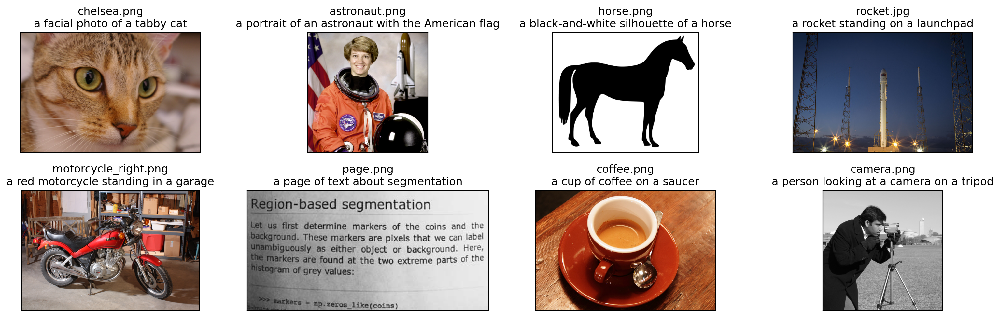

In [23]:
original_images = []
images = []
texts = []
plt.figure(figsize=(16, 5))

skimage.data.download_all(directory=None)
for filename in [filename for filename in os.listdir(skimage.data_dir) if filename.endswith(".png") or filename.endswith(".jpg")]:
    name = os.path.splitext(filename)[0]
    if name not in descriptions:
        continue

    image = Image.open(os.path.join(skimage.data_dir, filename)).convert("RGB")

    plt.subplot(2, 4, len(images) + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{descriptions[name]}")
    plt.xticks([])
    plt.yticks([])

    original_images.append(image)
    images.append(preprocess(image))
    texts.append(descriptions[name])

plt.tight_layout()


## Building features

We normalize the images, tokenize each text input, and run the forward pass of the model to get the image and text features.

In [32]:
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

## Calculating cosine similarity

We normalize the features and calculate the dot product of each pair.

Text(0.5, 1.0, 'Cosine similarity between text and image features(natural)')

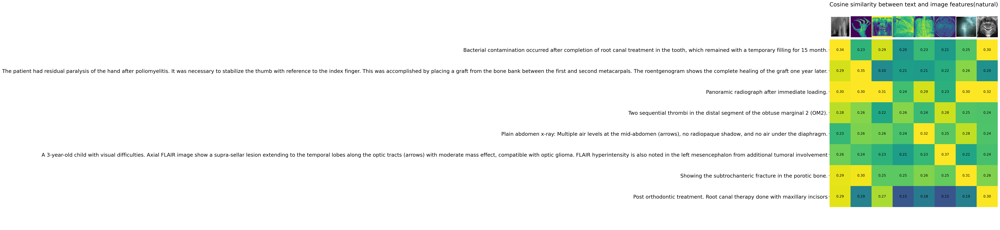

In [33]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(natural)", size=20)

## Performance of CLIP in medical domain

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

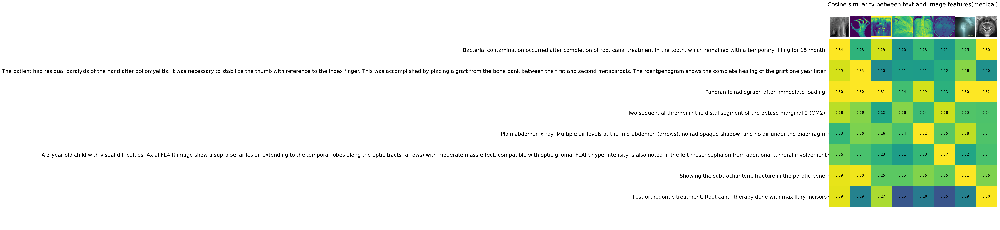

In [34]:
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join("/content/drive/My Drive/data2/pretrain_data/roco/train/radiology/images", filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)


# Zero-Shot Image Classification

You can classify images using the cosine similarity (times 100) as the logits to the softmax operation.

In [35]:
from torchvision.datasets import CIFAR100

cifar100 = CIFAR100(os.path.expanduser("~/.cache"), transform=preprocess, download=True)

In [36]:
text_descriptions = [f"This is a photo of a {label}" for label in cifar100.classes]
text_tokens = clip.tokenize(text_descriptions).cuda()

In [37]:
with torch.no_grad():
    text_features = model.encode_text(text_tokens).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

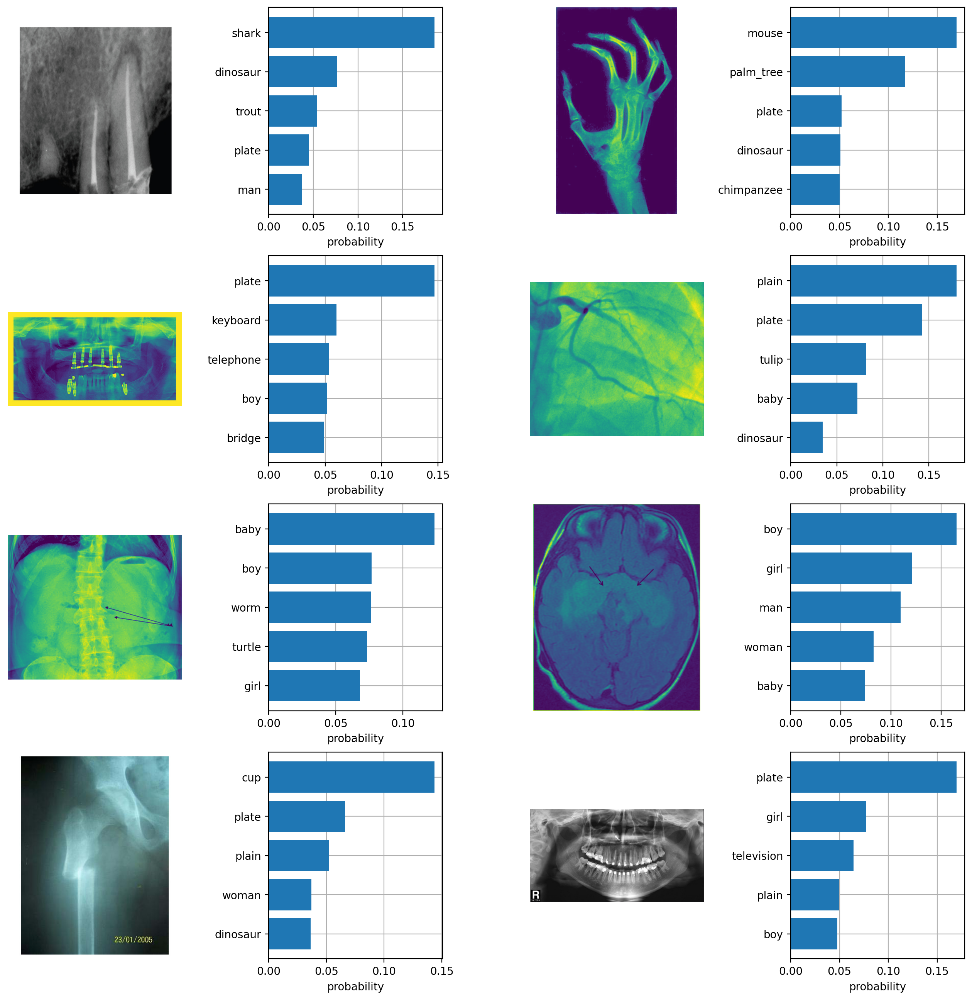

In [38]:
plt.figure(figsize=(16, 16))

for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [cifar100.classes[index] for index in top_labels[i].numpy()])
    plt.xlabel("probability")

plt.subplots_adjust(wspace=0.5)
plt.show()

# Fine-tuning CLIP on ROCO



In [18]:
# dataset location
csv_file ="/content/drive/My Drive/data2/roco-list.csv"
root_dir = "/content/drive/My Drive/data2/pretrain_data/roco/train/radiology/images"
val_csv_file = "/content/drive/My Drive/data2/local-val-list.csv"
val_root_dir = "/content/drive/My Drive/data2/pretrain_data/roco/val/radiology/images"

# train options
seed = 42
batch_size = 16
image_size = 224
start_epoch = 0
epochs = 10
visual_encoder = "clip@ViT-B/16"
learning_rate = 3e-6
model_path = "/content/drive/My Drive/model_checkpoint_CLIP_ROCO" # set to the directory containing `checkpoint_##.tar`


In [19]:
import os
import numpy as np
import pandas as pd
import torch
import torchvision
import datetime
import time
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset
import random
import clip



class CLRDataset(Dataset):
    """Contrastive Learning Representations Dataset."""

    def __init__(self, csv_file, root_dir, transform=None, clip=False):
        self.clr_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.clip = clip

    def __len__(self):
        return len(self.clr_frame)

    def text_sampling(self, text):
        text = text.replace("\n", " ")
        text = text.split(".")
        if '' in text:
            text.remove('')
        text = random.choice(text)
        return text

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir,
                                self.clr_frame.iloc[idx, 0]
                                )
        if not os.path.exists(img_name):
            img_name=img_name.replace('train','val')
        image = Image.open(img_name)
        if not self.clip:
            image = image.convert('RGB')
        text = self.clr_frame.iloc[idx, 1]
        name = self.clr_frame.iloc[idx, 0]
        sample = {'image': image, 'text': text,'name':name}
        if self.clip:
            sample = self.transform(sample['image']), sample['text'],sample['name'] #self.text_sampling(sample['text'])
        elif self.transform:
            sample = self.transform(sample)

        return sample


def load_optimizer( model, lr=3e-6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0, last_epoch=-1
    )
    return optimizer, scheduler


def train( train_loader, model, tokenizer, optimizer,truncation):
    loss_epoch = 0
    for step, (images, texts,name) in enumerate(train_loader):
        optimizer.zero_grad()
        x_v = images.to('cuda')
        x_u = tokenizer(list(texts), truncate=True).to('cuda')

        v,u=model(x_v,x_u)

        labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

        loss_img = torch.nn.CrossEntropyLoss()
        loss_txt = torch.nn.CrossEntropyLoss()

        img_loss = loss_img(v,labels)
        text_loss = loss_txt(u,labels)

        loss = (img_loss + text_loss)/2

        loss.backward()
        optimizer.step()

        if step % 500 == 0:
            print(f"Step [{step}/{len(train_loader)}]\t Loss: {loss.item()}")

        loss_epoch += loss.item()
    return loss_epoch



def validate( val_loader, model, tokenizer, optimizer, truncation):

    with torch.no_grad():
        model.eval()
        loss_epoch = 0
        for step, (x_v, x_u, _) in enumerate(val_loader):
            x_v = x_v.to('cuda')
            x_u = tokenizer(list(x_u), truncate=True).to('cuda')

            v,u=model(x_v,x_u)

            labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

            loss_img = torch.nn.CrossEntropyLoss()
            loss_txt = torch.nn.CrossEntropyLoss()

            img_loss = loss_img(v,labels)
            text_loss = loss_txt(u,labels)

            loss = (img_loss + text_loss)/2
            loss_epoch += loss.item()

    model.train()
    return loss_epoch


def main(gpu):

    is_master=True

    # set GPU device
    torch.cuda.set_device(gpu)
    torch.manual_seed(seed)
    np.random.seed(seed)

    # initialize model
    print("Initializing model... ", end="", flush=True)
    model, preprocess = clip.load(visual_encoder.split("@")[-1], device='cuda', jit=False)
    model.float()
    tokenizer=clip.tokenize
    train_fonction = train
    validate_fonction = validate

    # optimizer
    optimizer, scheduler = load_optimizer(model, lr=float(learning_rate))

    # initialize dataloader
    transform = preprocess
    print('Image_Transform',transform)
    train_dataset = CLRDataset(csv_file=csv_file,
                               root_dir=root_dir,
                               transform=transform,
                               clip = True
                               )

    val_dataset = CLRDataset(csv_file=val_csv_file,
                             root_dir=val_root_dir,
                             transform=transform,
                             clip = True
                             )

    train_sampler = None
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(train_sampler is None),
        drop_last=True,
        num_workers=8,
        sampler=train_sampler,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        drop_last=True,
        num_workers=8
    )

    print("[DONE]\n")
    print("STARTING TRAINING")
    print('Start Time =', datetime.datetime.now().strftime("%H:%M:%S"), '\n')

    t0 = time.time()
    global_step = 0
    current_epoch = 0
    best_val_loss = np.inf

    for epoch in range(0, epochs):
        if epoch<2:
            if train_sampler is not None:
                train_sampler.set_epoch(epoch)

            lr = optimizer.param_groups[0]["lr"]
            loss_epoch = train_fonction(train_loader, model, tokenizer, optimizer,True)

        if is_master:
            val_loss = validate_fonction( val_loader, model, tokenizer, optimizer, True)
            if val_loss < best_val_loss:
                torch.save(model.state_dict(), os.path.join(model_path, "best_checkpoint.pth"))
                best_val_loss = val_loss

            epoch_counter = epoch - 0
            elapsed = time.time() - t0
            epoch_time = elapsed/(epoch_counter+1)
            remaining = (epochs - (epoch_counter+1))*epoch_time
            remaining = str(datetime.timedelta(seconds=round(remaining)))
            elapsed = str(datetime.timedelta(seconds=round(elapsed)))
            print(f'Epoch {epoch_counter+1}/{epochs} [{elapsed}<{remaining}, {round(epoch_time, 2)}s/epoch] {round((epoch_counter+1)/epochs*100, 1)}% loss: {loss_epoch / len(train_loader)}\t val_loss: {val_loss / len(val_loader)} lr: {lr}')

            current_epoch += 1


if not os.path.exists(model_path):
    os.makedirs(model_path)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
main(0)

Device: cuda:0
Initializing model... 

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Image_Transform Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7a1332474cc0>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
[DONE]

STARTING TRAINING
Start Time = 14:21:51 

Step [0/4087]	 Loss: 1.6037728786468506
Step [500/4087]	 Loss: 0.9786286950111389
Step [1000/4087]	 Loss: 1.0350291728973389
Step [1500/4087]	 Loss: 0.9330504536628723
Step [2000/4087]	 Loss: 0.7408612370491028
Step [2500/4087]	 Loss: 0.7378091216087341
Step [3000/4087]	 Loss: 0.522644579410553
Step [3500/4087]	 Loss: 0.6310951709747314
Step [4000/4087]	 Loss: 0.3153192698955536
Epoch 1/10 [0:54:15<8:08:16, 3255.06s/epoch] 10.0% loss: 0.6371965562732872	 val_loss: 0.48399152773268084 lr: 3e-06
Step [0/4087]	 Loss: 0.39799195528030396
Step [500/4087]	 Loss: 0.08055409789085388
Step [1000/4087]	 Loss: 0.48533427715301514
Step [1500/4087]	 Los

## Performance of CLIP in medical domain(after fine-tuning on ROCO )

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

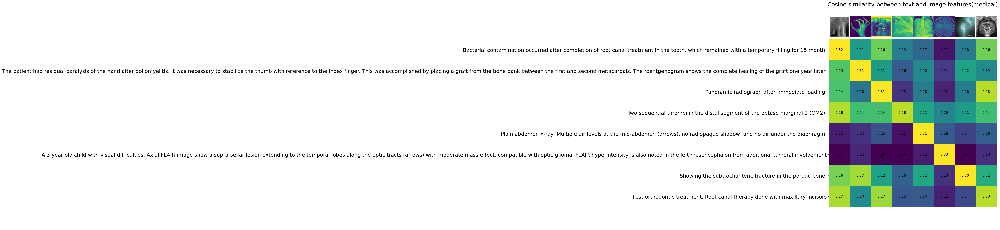

In [39]:
#load checkpoint
model.load_state_dict(torch.load('/content/drive/My Drive/data2/ViT-B-16_best_checkpoint_2.tar'))

#compute txt-img similarity again
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join(root_dir, filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)

# Comparatif des modèles de CLIP

Modèles CLIP disponibles : ['RN50', 'RN101', 'RN50x4', 'RN50x16', 'RN50x64', 'ViT-B/32', 'ViT-B/16', 'ViT-L/14', 'ViT-L/14@336px']


100%|██████████| 169M/169M [13:43<00:00, 205kB/s] 



--- Évaluation de RN50 ---


100%|███████████████████████████████████████| 244M/244M [00:13<00:00, 18.6MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(



--- Évaluation de RN101 ---


100%|███████████████████████████████████████| 278M/278M [00:14<00:00, 19.5MiB/s]


... (7 outputs left out)


--- Évaluation de ViT-L/14 ---


100%|███████████████████████████████████████| 890M/890M [00:44<00:00, 21.1MiB/s]



=== Résultats comparatifs (CIFAR-100 Zero-Shot) ===


,Modèle,Paramètres (M),Résolution,Top-1 Acc (%),Top-5 Acc (%),Temps (s)
6,ViT-L/14,427.6,224x224,78.6,94.0,7.53
5,ViT-B/16,149.6,224x224,69.6,88.2,2.23
4,ViT-B/32,151.3,224x224,65.1,88.0,1.23
1,RN101,119.7,224x224,48.7,79.4,1.60
3,RN50x16,291.0,384x384,47.3,73.6,9.78
2,RN50x4,178.3,288x288,47.1,72.7,3.66
0,RN50,102.0,224x224,41.1,71.8,1.81


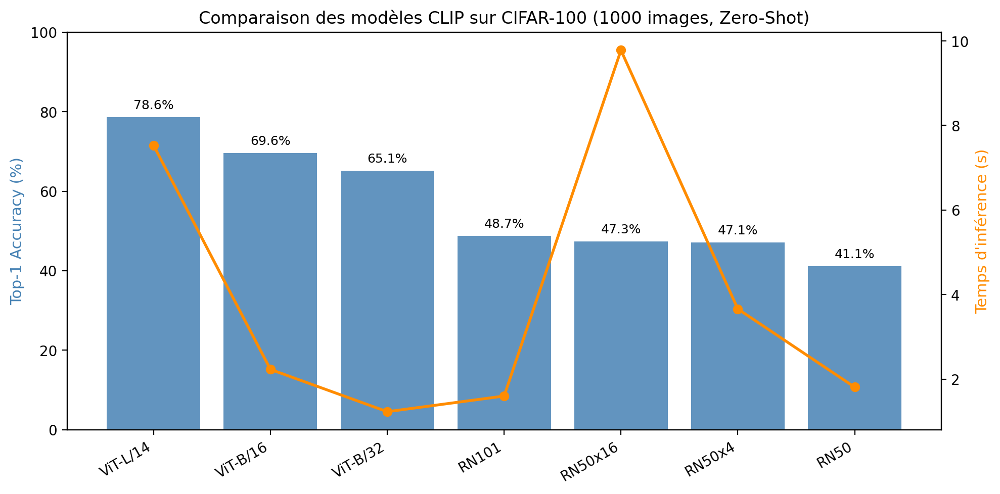

In [21]:
import gc
import time
import torch
import clip
import pandas as pd
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm

# 1. Lister tous les modèles disponibles dans CLIP
available_models = clip.available_models()
print("Modèles CLIP disponibles :", available_models)

# Tu peux tester tous les modèles, ou commenter les plus lourds (RN50x64, ViT-L/14@336px) si c'est trop long
models_to_evaluate = [
    'RN50',
    'RN101',
    'RN50x4',
    'RN50x16',
    'ViT-B/32',
    'ViT-B/16',
    'ViT-L/14',
    # 'RN50x64',        # Très lourd (~1.7 Go)
    # 'ViT-L/14@336px'  # Plus lent (résolution 336x336)
]

device = "cuda" if torch.cuda.is_available() else "cpu"
N_SAMPLES = 1000  # Nombre d'images de test CIFAR-100 (augmente à 10000 pour le dataset complet)
BATCH_SIZE = 64

# Téléchargement initial du dataset (sans transform, car chaque modèle a son propre preprocess)
base_dataset = CIFAR100(root="./data_cifar100", download=True, train=False)
class_names = base_dataset.classes
text_prompts = [f"a photo of a {c.replace('_', ' ')}" for c in class_names]

results = []

for model_name in models_to_evaluate:
    print(f"\n--- Évaluation de {model_name} ---")
    
    # Chargement du modèle et de son prétraitement spécifique
    model, preprocess = clip.load(model_name, device=device)
    model.eval()
    
    # Caractéristiques du modèle
    num_params = sum(p.numel() for p in model.parameters()) / 1e6
    input_res = model.visual.input_resolution
    
    # Préparation du DataLoader avec le preprocess du modèle courant
    dataset = CIFAR100(root="./data_cifar100", download=False, train=False, transform=preprocess)
    subset = Subset(dataset, range(N_SAMPLES))
    loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    
    # Encodage des prompts textuels (une seule fois par modèle)
    with torch.no_grad():
        text_tokens = clip.tokenize(text_prompts).to(device)
        text_features = model.encode_text(text_tokens)
        text_features /= text_features.norm(dim=-1, keepdim=True)
    
    # Évaluation Zero-Shot
    top1_correct = 0
    top5_correct = 0
    total = 0
    
    start_time = time.time()
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=model_name, leave=False):
            images = images.to(device)
            labels = labels.to(device)
            
            image_features = model.encode_image(images)
            image_features /= image_features.norm(dim=-1, keepdim=True)
            
            # Similarité cosinus
            logits = 100.0 * image_features @ text_features.T
            
            # Top-1 et Top-5
            _, top5_preds = logits.topk(5, dim=-1)
            top1_correct += (top5_preds[:, 0] == labels).sum().item()
            top5_correct += (top5_preds == labels.unsqueeze(1)).any(dim=1).sum().item()
            total += labels.size(0)
            
    elapsed_time = time.time() - start_time
    top1_acc = 100.0 * top1_correct / total
    top5_acc = 100.0 * top5_correct / total
    
    results.append({
        "Modèle": model_name,
        "Paramètres (M)": round(num_params, 1),
        "Résolution": f"{input_res}x{input_res}",
        "Top-1 Acc (%)": round(top1_acc, 2),
        "Top-5 Acc (%)": round(top5_acc, 2),
        "Temps (s)": round(elapsed_time, 2)
    })
    
    # Libération de la mémoire GPU avant le modèle suivant
    del model, text_features, image_features, logits
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 2. Affichage du tableau comparatif
df_results = pd.DataFrame(results).sort_values(by="Top-1 Acc (%)", ascending=False)
print("\n=== Résultats comparatifs (CIFAR-100 Zero-Shot) ===")
display(df_results)

# 3. Graphique comparatif (Précision vs Temps d'inférence)
fig, ax1 = plt.subplots(figsize=(10, 5))

x = range(len(df_results))
bars = ax1.bar(x, df_results["Top-1 Acc (%)"], color="steelblue", alpha=0.85, label="Top-1 Accuracy (%)")
ax1.set_ylabel("Top-1 Accuracy (%)", color="steelblue", fontsize=11)
ax1.set_xticks(x)
ax1.set_xticklabels(df_results["Modèle"], rotation=30, ha="right")
ax1.set_ylim(0, 100)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=9)

ax2 = ax1.twinx()
ax2.plot(x, df_results["Temps (s)"], color="darkorange", marker="o", linewidth=2, label="Temps d'inférence (s)")
ax2.set_ylabel("Temps d'inférence (s)", color="darkorange", fontsize=11)

plt.title(f"Comparaison des modèles CLIP sur CIFAR-100 ({N_SAMPLES} images, Zero-Shot)")
fig.tight_layout()
plt.show()

# Test sur images naturelles ( pas CIFAR-100 )

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
100%|██████████| 792M/792M [00:41<00:00, 18.9MB/s] 
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.0MB/s]


Dataset : Oxford-IIIT Pet | 3669 images de test | 37 classes


Évaluation ViT-B/16 sur Oxford-IIIT Pet: 100%|██████████| 58/58 [00:12<00:00,  4.73it/s]



=== Résultats Zero-Shot (ViT-B/16) sur Oxford-IIIT Pet ===
Top-1 Accuracy : 88.39% (3243/3669)
Top-5 Accuracy : 99.43% (3648/3669)


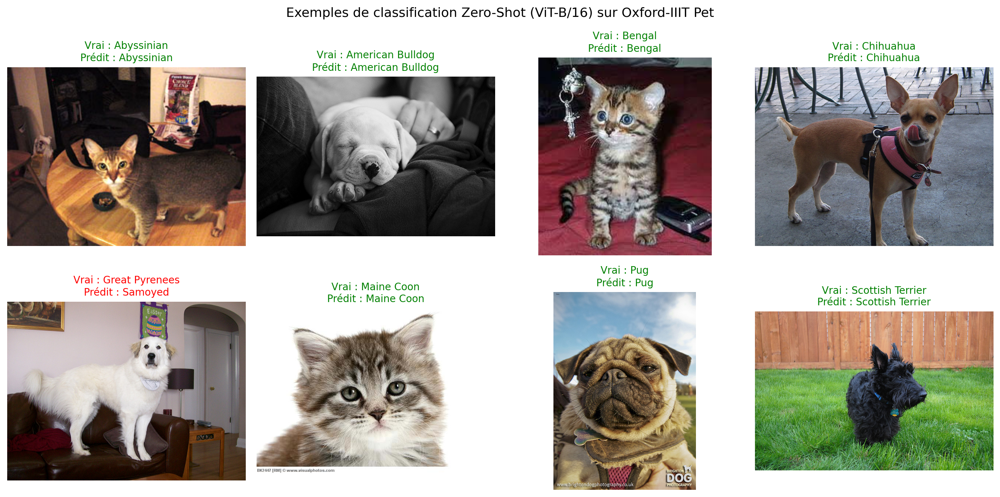

In [40]:
import torch
import clip
import matplotlib.pyplot as plt
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader
from tqdm import tqdm

# 1. Chargement du modèle CLIP (tu peux aussi tester "ViT-L/14")
device = "cuda" if torch.cuda.is_available() else "cpu"
model_name = "ViT-B/16"
model, preprocess = clip.load(model_name, device=device)
model.eval()

# 2. Chargement du jeu de données Oxford-IIIT Pet (split de test : 3 669 images, 37 classes)
dataset = OxfordIIITPet(root="./data_pets", split="test", download=True, transform=preprocess)
raw_dataset = OxfordIIITPet(root="./data_pets", split="test", download=False)  # Pour l'affichage des images
loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=2)

class_names = dataset.classes
print(f"Dataset : Oxford-IIIT Pet | {len(dataset)} images de test | {len(class_names)} classes")

# 3. Encodage des prompts textuels (adaptés au domaine des animaux de compagnie)
text_prompts = [f"a photo of a {c}, a type of pet" for c in class_names]
with torch.no_grad():
    text_tokens = clip.tokenize(text_prompts).to(device)
    text_features = model.encode_text(text_tokens)
    text_features /= text_features.norm(dim=-1, keepdim=True)

# 4. Évaluation Zero-Shot (Top-1 et Top-5 Accuracy)
top1_correct = 0
top5_correct = 0
total = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(loader, desc=f"Évaluation {model_name} sur Oxford-IIIT Pet"):
        images = images.to(device)
        labels = labels.to(device)

        image_features = model.encode_image(images)
        image_features /= image_features.norm(dim=-1, keepdim=True)

        # Similarité cosinus
        logits = 100.0 * image_features @ text_features.T
        _, top5_preds = logits.topk(5, dim=-1)

        top1_correct += (top5_preds[:, 0] == labels).sum().item()
        top5_correct += (top5_preds == labels.unsqueeze(1)).any(dim=1).sum().item()
        total += labels.size(0)

        all_preds.extend(top5_preds[:, 0].cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

top1_acc = 100.0 * top1_correct / total
top5_acc = 100.0 * top5_correct / total

print(f"\n=== Résultats Zero-Shot ({model_name}) sur Oxford-IIIT Pet ===")
print(f"Top-1 Accuracy : {top1_acc:.2f}% ({top1_correct}/{total})")
print(f"Top-5 Accuracy : {top5_acc:.2f}% ({top5_correct}/{total})")

# 5. Visualisation de quelques prédictions (pour illustrer le compte-rendu)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
indices = [0, 100, 500, 1000, 1500, 2000, 2500, 3000]

for ax, idx in zip(axes.flat, indices):
    img, true_idx = raw_dataset[idx]
    pred_idx = all_preds[idx]
    color = "green" if pred_idx == true_idx else "red"
    
    ax.imshow(img)
    ax.set_title(f"Vrai : {class_names[true_idx]}\nPrédit : {class_names[pred_idx]}", color=color, fontsize=10)
    ax.axis("off")

plt.suptitle(f"Exemples de classification Zero-Shot ({model_name}) sur Oxford-IIIT Pet", fontsize=13)
plt.tight_layout()
plt.show()